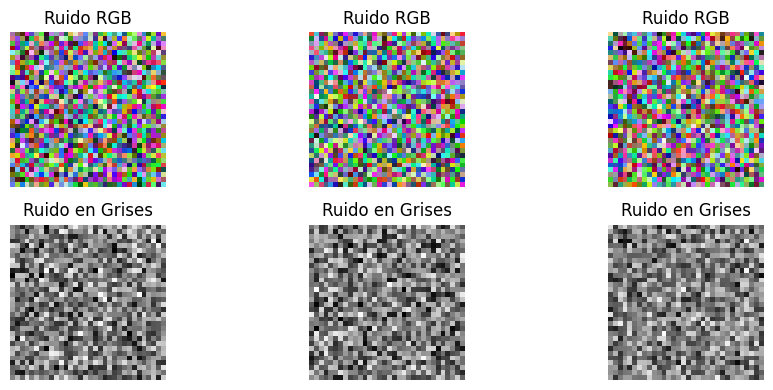

In [2]:
import tensorflow as tf
import matplotlib.pyplot as plt

# 1. Capa personalizada (sin pesos entrenables)
class CapaEscalaGrises(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super(CapaEscalaGrises, self).__init__(**kwargs)

    def call(self, inputs):
        pesos_rgb = tf.constant([0.2989, 0.5870, 0.1140], dtype=inputs.dtype)
        grises = tf.reduce_sum(inputs * pesos_rgb, axis=-1, keepdims=True)
        return grises

# 2. Pruebas con ruido RGB aleatorio
# Tamaño: 3 imágenes, 32x32 píxeles, 3 canales (Color)
imagenes_prueba = tf.random.uniform(shape=(3, 32, 32, 3), minval=0.0, maxval=1.0)

capa_grises = CapaEscalaGrises()
imagenes_transformadas = capa_grises(imagenes_prueba)

# 3. Visualización
plt.figure(figsize=(10, 4))
for i in range(3):
    plt.subplot(2, 3, i + 1)
    plt.imshow(imagenes_prueba[i]) # Se verá como estática de colores
    plt.title("Ruido RGB")
    plt.axis("off")

    plt.subplot(2, 3, i + 4)
    plt.imshow(tf.squeeze(imagenes_transformadas[i]), cmap="gray") # Se verá como estática blanco y negro
    plt.title("Ruido en Grises")
    plt.axis("off")

plt.tight_layout()
plt.show()